# Ciclo de Vida de un Proyecto de Machine Learning
Este cuaderno presenta el flujo completo de trabajo para el análisis y modelado del conjunto de datos de viviendas de California, estructurado en sus **4 módulos metodológicos**.

## 1. Carga de Datos y Configuración del Entorno
En esta primera fase se preparan las librerías de trabajo y se adquieren los datos desde la fuente remota.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Blues_d")
pd.set_option("display.float_format", "{:,.2f}".format)
print("Librerías listas")

Librerías listas


> **Resumen del bloque:** Se importan las librerías necesarias (`numpy`, `pandas`, `matplotlib`, `seaborn`) y se configuran los estilos gráficos y el formato de visualización numérico.

In [2]:
url="https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
datos=pd.read_csv(url)
datos.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.00,880.00,129.00,322.00,126.00,8.33,"452,600.00",NEAR BAY
1,-122.22,37.86,21.00,"7,099.00","1,106.00","2,401.00","1,138.00",8.30,"358,500.00",NEAR BAY
2,-122.24,37.85,52.00,"1,467.00",190.00,496.00,177.00,7.26,"352,100.00",NEAR BAY
3,-122.25,37.85,52.00,"1,274.00",235.00,558.00,219.00,5.64,"341,300.00",NEAR BAY
4,-122.25,37.85,52.00,"1,627.00",280.00,565.00,259.00,3.85,"342,200.00",NEAR BAY


> **Resumen del bloque:** Se define la URL del dataset de viviendas de California en GitHub, se carga en el DataFrame `datos` y se visualizan sus primeras 5 filas para comprobar la lectura.

## 2. Análisis Exploratorio de Datos (EDA)
En esta segunda fase se explora a fondo el conjunto de datos para comprender sus variables, distribuciones, relaciones y posibles problemas (nulos, valores atípicos).

In [3]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


> **Resumen del bloque:** Se inspecciona la estructura general del dataset con `.info()`: número de filas (20.640), columnas, tipos de datos y recuento de valores no nulos.

In [4]:
print("Valores nulos por columna: ")
print(datos.isna().sum())
print("\nFilas duplicados", datos.duplicated().sum())

Valores nulos por columna: 
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Filas duplicados 0


> **Resumen del bloque:** Se verifica la calidad inicial de los datos: se cuentan los valores nulos por columna (207 en `total_bedrooms`) y se comprueba que no existan filas duplicadas (0).

In [5]:
datos.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.00",-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,"20,640.00",35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,"20,640.00",28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,"20,640.00","2,635.76","2,181.62",2.00,"1,447.75","2,127.00","3,148.00","39,320.00"
total_bedrooms,"20,433.00",537.87,421.39,1.00,296.00,435.00,647.00,"6,445.00"
population,"20,640.00","1,425.48","1,132.46",3.00,787.00,"1,166.00","1,725.00","35,682.00"
households,"20,640.00",499.54,382.33,1.00,280.00,409.00,605.00,"6,082.00"
median_income,"20,640.00",3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,"20,640.00","206,855.82","115,395.62","14,999.00","119,600.00","179,700.00","264,725.00","500,001.00"


> **Resumen del bloque:** Se calculan las estadísticas descriptivas numéricas con `.describe().T` (media, desviación estándar, valores mínimos, cuartiles y máximos).

In [6]:
datos["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

> **Resumen del bloque:** Se analiza la frecuencia de cada categoría de la variable cualitativa `ocean_proximity` con `.value_counts()`.

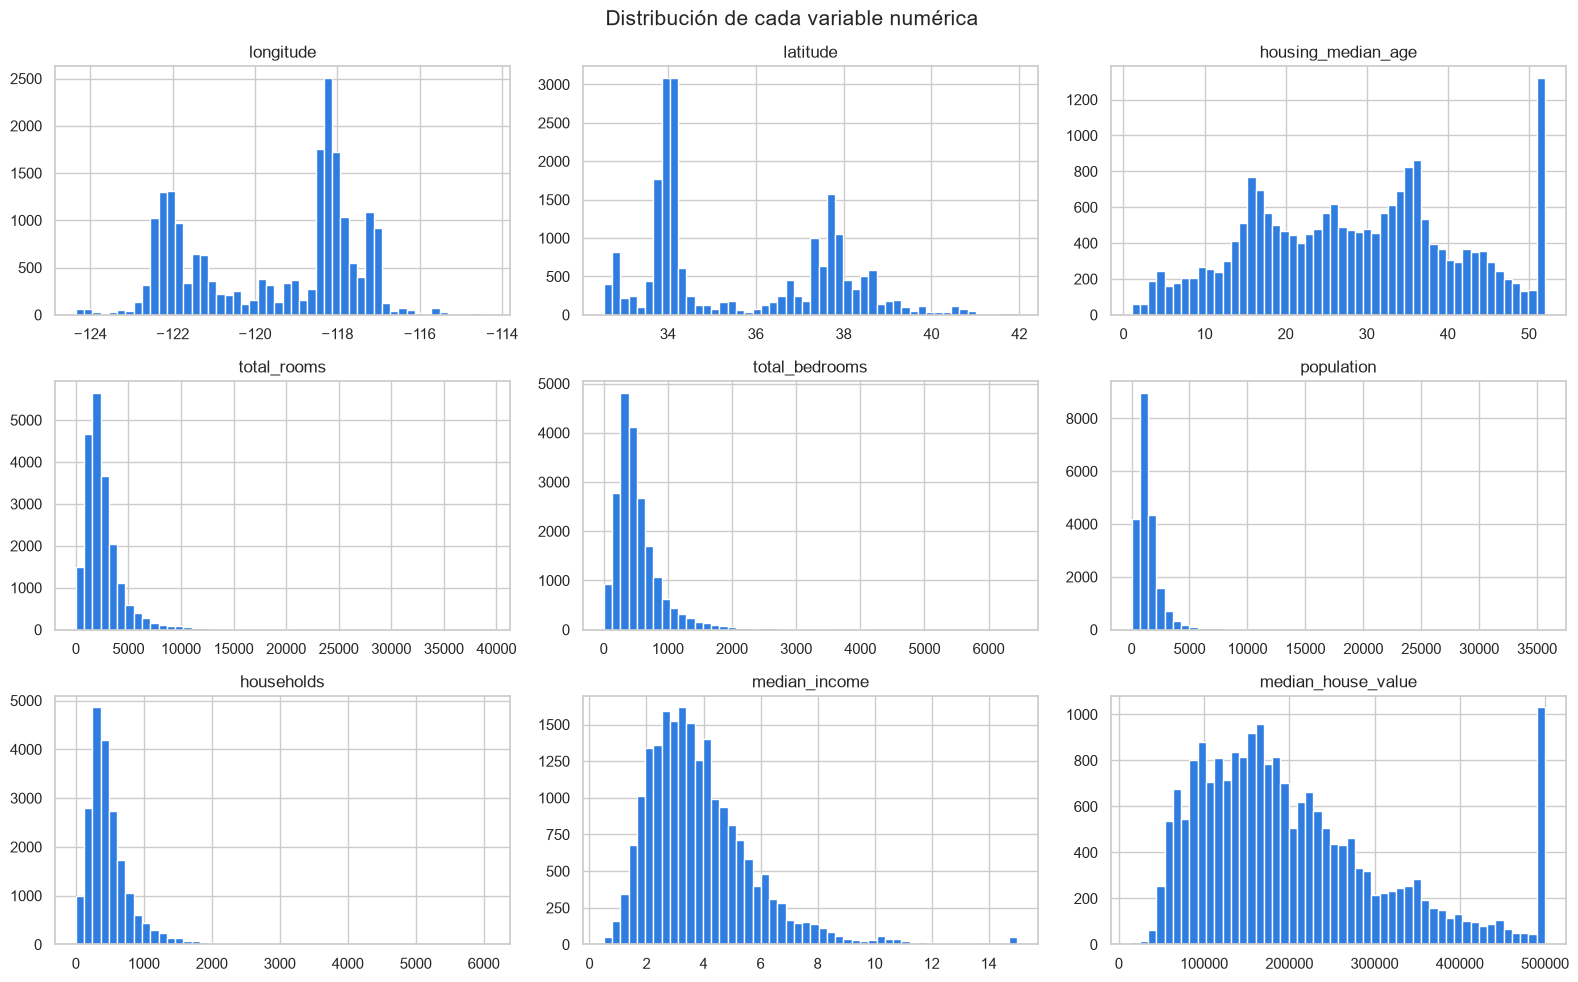

In [7]:
datos.hist(bins=50, figsize=(16,10), color="#2F7DE1")
plt.suptitle("Distribución de cada variable numérica", fontsize=15)
plt.tight_layout()
plt.show()

> **Resumen del bloque:** Se generan los histogramas de todas las columnas numéricas para observar sus distribuciones, asimetrías y concentraciones.

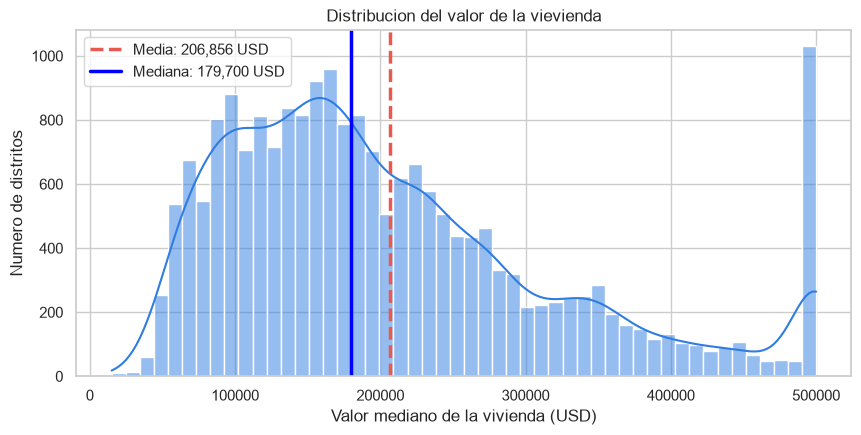

Distritos con el valor tope de $500.001 USD. 965


In [8]:
media = datos["median_house_value"].mean()
mediana = datos["median_house_value"].median()

plt.figure(figsize=(10, 4.5))
sns.histplot(datos["median_house_value"], bins=50, kde=True, color="#2F7DE1")
plt.axvline(media, color="#E85A4F", linestyle="--", linewidth=2.5, label=f"Media: {media:,.0f} USD")
plt.axvline(mediana, color="#0000FF", linewidth=2.5, label=f"Mediana: {mediana:,.0f} USD")
plt.title("Distribucion del valor de la vievienda")
plt.xlabel("Valor mediano de la vivienda (USD)")
plt.ylabel("Numero de distritos")
plt.legend()
plt.show()

print("Distritos con el valor tope de $500.001 USD.", (datos["median_house_value"]>= 500001).sum())

> **Resumen del bloque:** Se analiza detalladamente la variable objetivo (`median_house_value`), graficando su distribución con media y mediana, e identificando 965 distritos topados artificialmente en $500.001 USD.

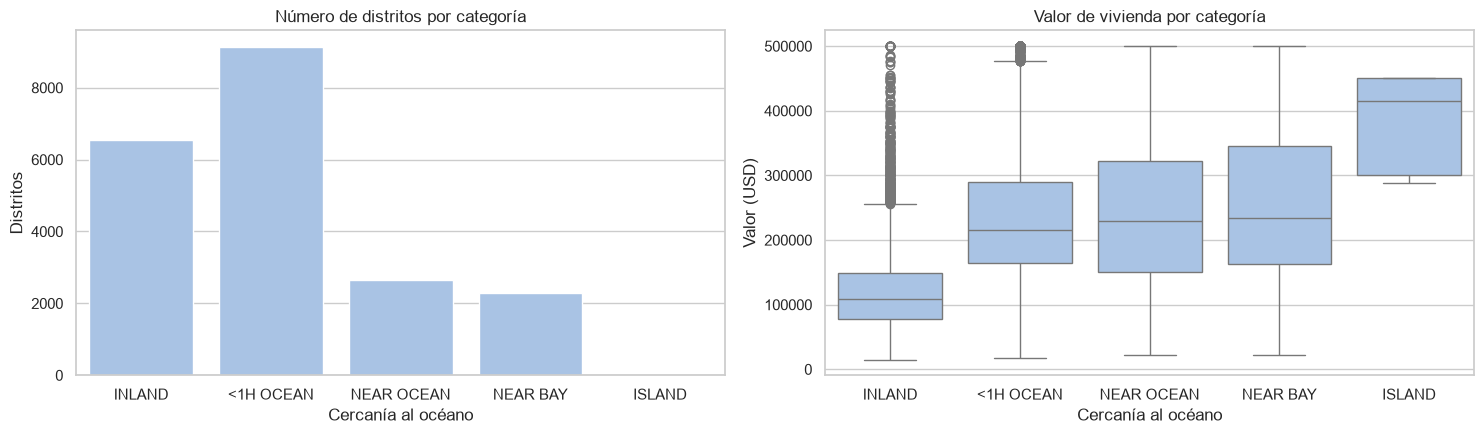

,count,median,mean
ocean_proximity,,,
<1H OCEAN,9136,"214,850.00","240,084.29"
INLAND,6551,"108,500.00","124,805.39"
ISLAND,5,"414,700.00","380,440.00"
NEAR BAY,2290,"233,800.00","259,212.31"
NEAR OCEAN,2658,"229,450.00","249,433.98"


In [9]:
orden = datos.groupby("ocean_proximity")["median_house_value"].median().sort_values().index

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

sns.countplot(data=datos, x="ocean_proximity", order=orden, color="#9FC2EE", ax=ax[0])
ax[0].set(title="Número de distritos por categoría", xlabel="Cercanía al océano", ylabel="Distritos")

sns.boxplot(data=datos, x="ocean_proximity", y="median_house_value", order=orden, color="#9FC2EE", ax=ax[1])
ax[1].set(title="Valor de vivienda por categoría", xlabel="Cercanía al océano", ylabel="Valor (USD)")

plt.tight_layout()
plt.show()

datos.groupby("ocean_proximity")["median_house_value"].agg(['count', 'median', 'mean'])

> **Resumen del bloque:** Se examina la relación entre la cercanía al océano y el precio de las viviendas utilizando diagramas de barras, diagramas de caja (*boxplot*) y agregaciones numéricas.

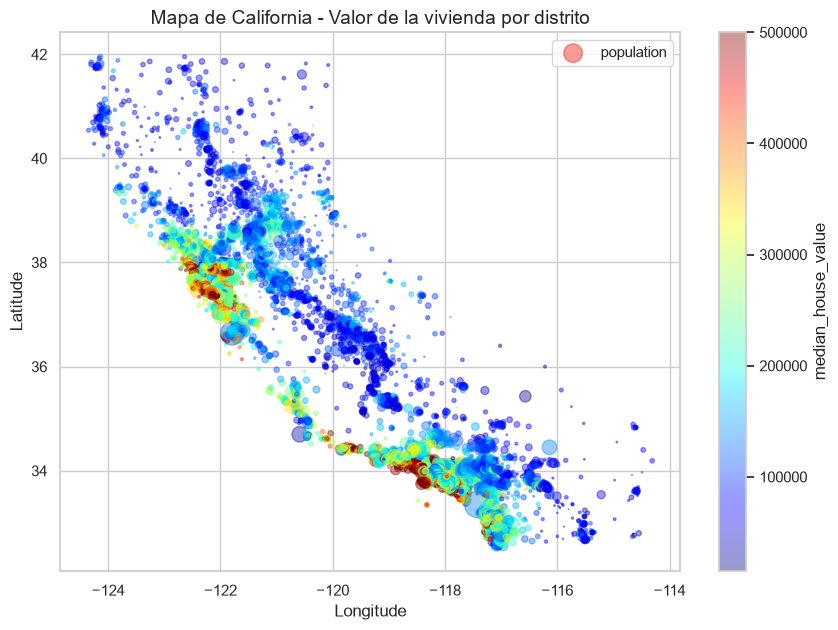

In [10]:
datos.plot(kind="scatter", x="longitude", y="latitude", alpha=0.4,
    s=datos["population"]/100, label="population", figsize=(10,7),
    c="median_house_value", cmap=plt.get_cmap("jet"), colorbar=True,
)
plt.legend()
plt.ylabel("Latitude")
plt.xlabel("Longitude")
plt.title("Mapa de California - Valor de la vivienda por distrito", fontsize=14)
plt.show()

> **Resumen del bloque:** Se traza el mapa geográfico de California mediante un gráfico de dispersión (latitud vs. longitud), donde el tamaño del punto representa la población y el color indica el precio de la vivienda.

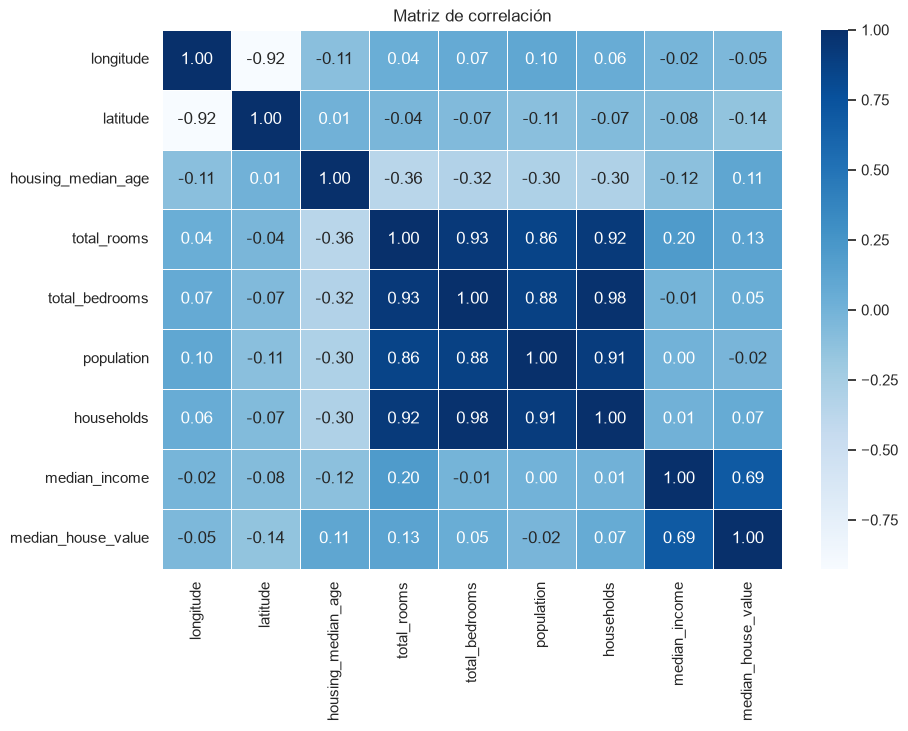

median_house_value    1.00
median_income         0.69
total_rooms           0.13
housing_median_age    0.11
households            0.07
total_bedrooms        0.05
population           -0.02
longitude            -0.05
latitude             -0.14
Name: median_house_value, dtype: float64

In [11]:
correlacion = datos.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="Blues", linewidths=0.5)
plt.title("Matriz de correlación")
plt.show()

correlacion["median_house_value"].sort_values(ascending=False)

> **Resumen del bloque:** Se calcula la matriz de correlación numérica y se dibuja un mapa de calor (*heatmap*), evidenciando que el ingreso mediano (`median_income`) es la variable con mayor correlación lineal con el precio (0.69).

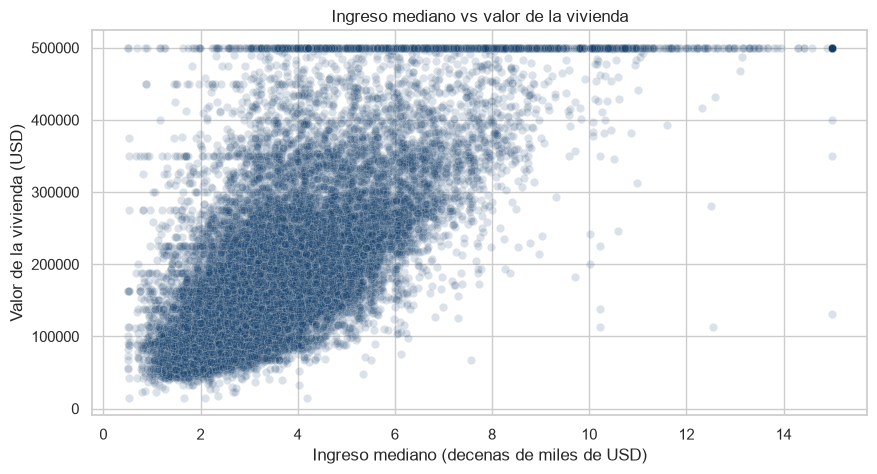

In [12]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=datos, x="median_income", y="median_house_value", alpha=0.15, color="#123C68")
plt.title("Ingreso mediano vs valor de la vivienda")
plt.xlabel("Ingreso mediano (decenas de miles de USD)")
plt.ylabel("Valor de la vivienda (USD)")
plt.show()

> **Resumen del bloque:** Se profundiza en la relación ingreso mediano vs. precio de la vivienda con un gráfico de dispersión, corroborando la tendencia ascendente y el corte artificial en 500k.

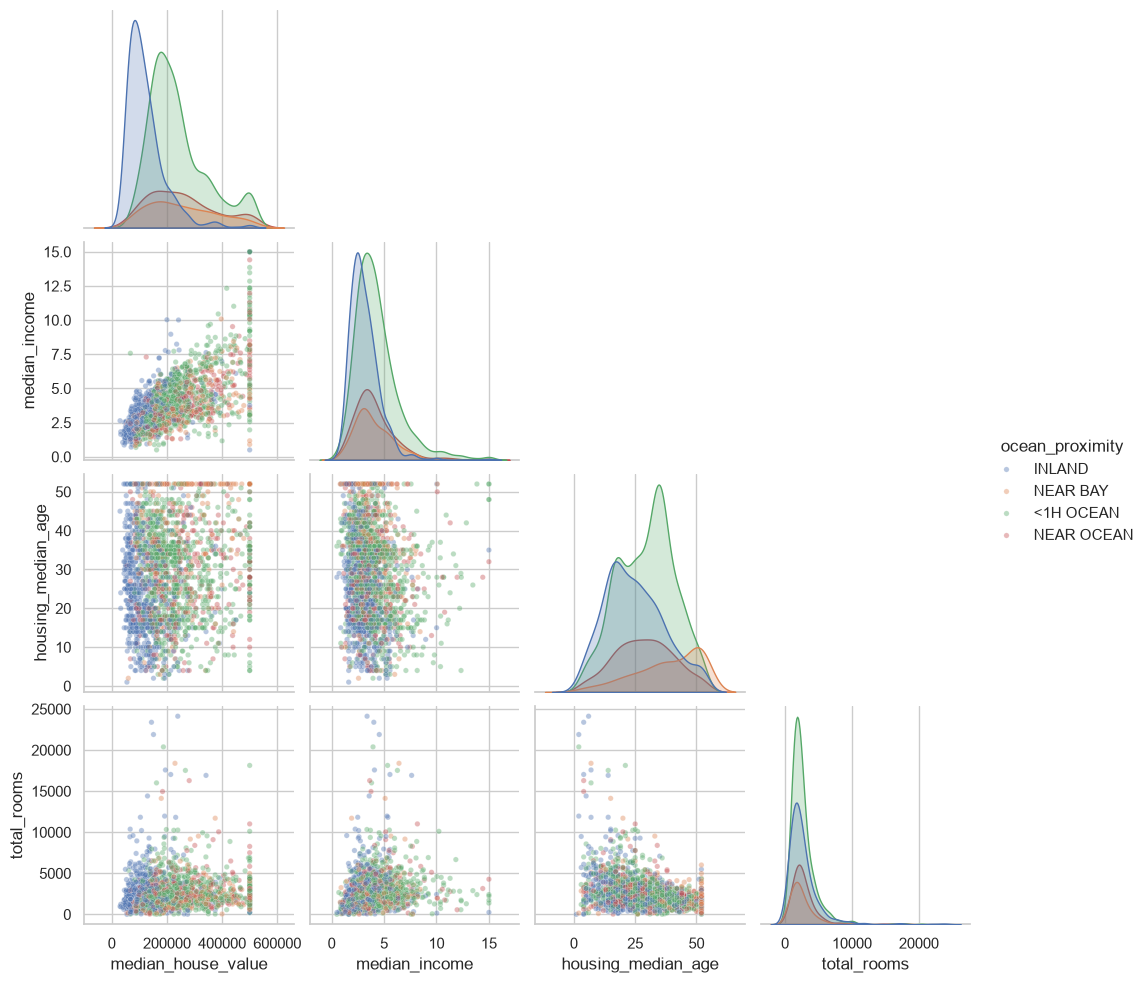

In [13]:
muestra = datos.sample(2000, random_state=42)

sns.pairplot(
    muestra,
    vars=['median_house_value', 'median_income', 'housing_median_age', 'total_rooms'],
    hue='ocean_proximity',
    palette='deep',
    plot_kws={'alpha': 0.4, 's': 15},
    corner=True
)

plt.show()

> **Resumen del bloque:** Se genera un gráfico de pares (*pairplot*) sobre una muestra aleatoria de 2.000 distritos para evaluar relaciones multivariadas entre las principales características según la cercanía al mar.

## 3. Limpieza y Preparación de Datos (Preprocesamiento & Feature Engineering)
En esta tercera fase se corrigen inconsistencias, se tratan nulos y valores atípicos, se construyen nuevas variables más informativas y se preparan los datos para los modelos matemáticos.

In [14]:
limpios = datos.copy()
filas_iniciales = len(limpios)
print("Filas iniciales:", filas_iniciales)

Filas iniciales: 20640


> **Resumen del bloque:** Se crea una copia del dataset llamada `limpios` para aislar las transformaciones y se almacena el recuento de filas iniciales (20.640).

In [15]:
mediana_dormitorios = limpios["total_bedrooms"].median()
limpios["total_bedrooms"] = limpios["total_bedrooms"].fillna(mediana_dormitorios)
print("Mediana usada:", mediana_dormitorios)
print("Nulos restantes: ", limpios["total_bedrooms"].isna().sum())

Mediana usada: 435.0
Nulos restantes:  0


> **Resumen del bloque:** Se imputan los 207 valores faltantes de `total_bedrooms` sustituyéndolos por la mediana (435.0) para no perder esas filas.

In [16]:
limpios = limpios[limpios["median_house_value"]<500001]
print("Filas después de quitar el tope:", len(limpios))

Filas después de quitar el tope: 19675


> **Resumen del bloque:** Se filtran y eliminan los distritos cuyo valor de vivienda es igual o superior a $500.001 USD para evitar distorsiones por el límite artificial de la encuesta.

In [17]:
limpios = limpios[limpios["ocean_proximity"]!= "ISLAND"].copy()
print("Filas después de quitar ISLAND: ", len(limpios))

Filas después de quitar ISLAND:  19670


> **Resumen del bloque:** Se retiran los 5 registros pertenecientes a la categoría `ISLAND` debido a que es una muestra insignificante para generalizar patrones.

In [18]:
limpios["habitaciones_por_hogar"] = limpios["total_rooms"] / limpios["households"]
limpios["dormitorios_por_habitacion"] = limpios["total_bedrooms"] / limpios["total_rooms"]
limpios["personas_por_hogar"] = limpios["population"] / limpios["households"]

nuevas = ["habitaciones_por_hogar", "dormitorios_por_habitacion", "personas_por_hogar"]
limpios[nuevas].describe().T

,count,mean,std,min,25%,50%,75%,max
habitaciones_por_hogar,"19,670.00",5.36,2.29,0.85,4.41,5.18,5.97,132.53
dormitorios_por_habitacion,"19,670.00",0.22,0.06,0.04,0.18,0.20,0.24,2.82
personas_por_hogar,"19,670.00",3.10,10.63,0.69,2.45,2.84,3.31,"1,243.33"


> **Resumen del bloque:** Se aplica ingeniería de características creando 3 nuevas variables relativas: habitaciones por hogar, dormitorios por habitación y personas por hogar.

In [19]:
for col in nuevas:
    p1, p99 = np.percentile(limpios[col], [1, 99])
    limpios[col] = np.clip(limpios[col], p1, p99)
limpios[nuevas].describe().T

,count,mean,std,min,25%,50%,75%,max
habitaciones_por_hogar,"19,670.00",5.27,1.27,2.58,4.41,5.18,5.97,10.36
dormitorios_por_habitacion,"19,670.00",0.21,0.05,0.13,0.18,0.20,0.24,0.42
personas_por_hogar,"19,670.00",2.94,0.73,1.56,2.45,2.84,3.31,5.41


> **Resumen del bloque:** Se realiza tratamiento de valores atípicos (*clipping*) en las 3 nuevas columnas, acotándolas entre el percentil 1% y el percentil 99%.

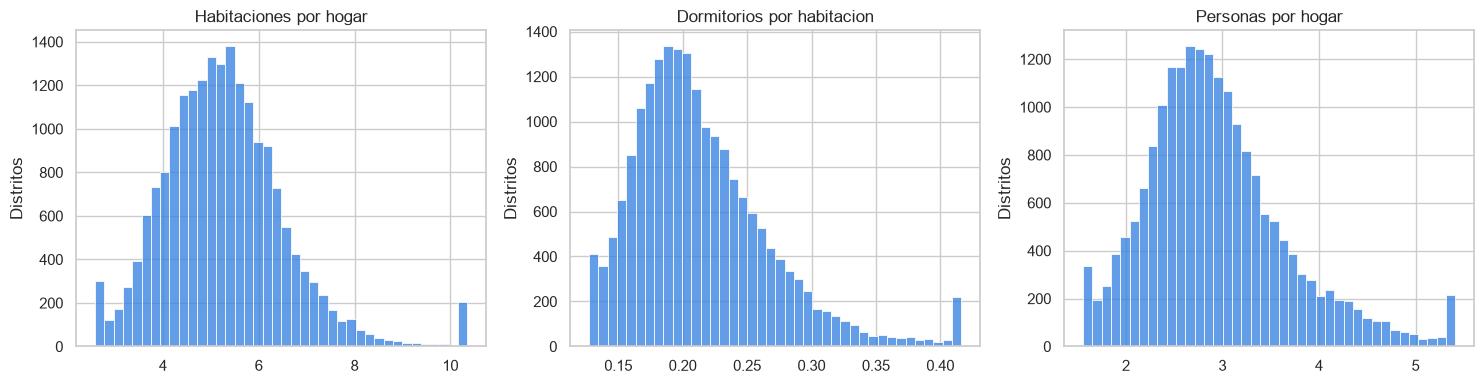

habitaciones_por_hogar        0.22
dormitorios_por_habitacion   -0.23
personas_por_hogar           -0.25
median_house_value            1.00
Name: median_house_value, dtype: float64

In [20]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
for i, col in enumerate(nuevas):
    sns.histplot(limpios[col],bins = 40, color="#2F7DE1", ax=ax[i])
    ax[i].set(title=col.replace("_"," ").capitalize(), xlabel="",
              ylabel="Distritos")
plt.tight_layout()
plt.show()

limpios[nuevas + ["median_house_value"]].corr()["median_house_value"]

> **Resumen del bloque:** Se visualizan los histogramas de las nuevas variables acotadas y se revisa su correlación con la variable objetivo.

In [21]:
antes =limpios.memory_usage(deep=True).sum() /1e6
limpios["ocean_proximity"] = limpios["ocean_proximity"].astype("category")
despues =limpios.memory_usage(deep=True).sum() /1e6
print("Memoria: ", antes, "MB -->", despues, "MB")

Memoria:  2.363307 MB --> 2.065416 MB


> **Resumen del bloque:** Se optimiza el uso de memoria RAM convirtiendo la columna categórica `ocean_proximity` al tipo `category` (de 3.16 MB a 2.06 MB).

In [22]:
modelo_datos = pd.get_dummies(limpios, columns=["ocean_proximity"], drop_first=True, dtype=int)
modelo_datos.filter(like="ocean_proximity").head()

,ocean_proximity_INLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0,1,0
1,0,1,0
2,0,1,0
3,0,1,0
4,0,1,0


> **Resumen del bloque:** Se aplica codificación *One-Hot Encoding* con `pd.get_dummies` (descartando la primera categoría) para transformar las categorías de texto en variables numéricas binarias (0 y 1).

In [23]:
resumen = pd.DataFrame({
    "Paso": ["Datos originales", "Nulos rellenados (207)",
             "Sin valores tope", "Sin categoría ISLAND"],
    "Filas": [filas_iniciales, filas_iniciales,
              filas_iniciales - (datos["median_house_value"] >= 500001).sum(),
              len(limpios)],
})
resumen

,Paso,Filas
0,Datos originales,20640
1,Nulos rellenados (207),20640
2,Sin valores tope,19675
3,Sin categoría ISLAND,19670


> **Resumen del bloque:** Se construye y muestra un DataFrame resumen con el impacto de cada paso de limpieza sobre el conteo de filas (concluyendo en 19.670 filas listas).

## 4. Modelado y Evaluación
En esta cuarta fase se divide la muestra, se define una línea base de comparación y se entrenan y evalúan modelos de Machine Learning (Regresión Lineal y Random Forest).

In [24]:
from sklearn.model_selection import train_test_split

x = modelo_datos.drop(columns=["median_house_value"])
y = modelo_datos["median_house_value"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("Entrenamiento:", x_train.shape, "| Prueba:", x_test.shape)

Entrenamiento: (15736, 14) | Prueba: (3934, 14)


> **Resumen del bloque:** Se separan las variables predictoras ($X$) de la variable objetivo ($y$), y se dividen en conjuntos de entrenamiento (80%, 15.736 filas) y prueba (20%, 3.934 filas) mediante `train_test_split`.

In [25]:
from sklearn.metrics import mean_absolute_error, r2_score
prediccion_base = np.full(len(y_test), y_train.mean())
print("Línea base -> MAE: ", mean_absolute_error(y_test, prediccion_base))

Línea base -> MAE:  78923.14372104131


> **Resumen del bloque:** Se calcula la línea base (*baseline*) asignando a cada predicción el valor promedio de entrenamiento, y se evalúa su error absoluto medio (MAE: ~$78.923 USD).

In [26]:
# Modelo de regresión lineal
from sklearn.linear_model import LinearRegression

lineal = LinearRegression()
lineal.fit(x_train, y_train)
pred_lineal = lineal.predict(x_test)
print("Regresión lineal -> MAE: ",
      mean_absolute_error(y_test, pred_lineal),
      "| R2: ", r2_score(y_test, pred_lineal))

Regresión lineal -> MAE:  43580.281358287815 | R2:  0.6446403522523986


> **Resumen del bloque:** Se entrena y evalúa un modelo de Regresión Lineal tradicional, alcanzando un MAE de ~$43.580 USD y un $R^2$ de ~0.64.

In [27]:
# Modelo Random Forest
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)
pred_rf = rf.predict(x_test)

print("Random Forest -> MAE: ",
      mean_absolute_error(y_test, pred_rf),
      "| R2: ", r2_score(y_test, pred_rf))

Random Forest -> MAE:  29965.114095068635 | R2:  0.7920438442583841


> **Resumen del bloque:** Se entrena y evalúa un ensamble Random Forest de 100 árboles de decisión, logrando una mejora notable con un MAE de ~$29.965 USD y un $R^2$ de ~0.79.